In [1]:
from lights.models import Model
from lights.fits import profile_logLL_scan
from lights.plotting import plot_contours, setup_style
from lights.paths import PLOTS_DIR

import numpy as np
import matplotlib.pyplot as plt

SAVE_DIR = PLOTS_DIR / "coupling_fits"
setup_style()

In [2]:
def contour_figure(scan, scale, xlabel, ylabel, mass_label, title, file, **contour_options):
    """Single-panel figure of a coupling scan: Belle II, BaBar (LEP) and combined contours, with legends.

    scale: the value of the plotted coupling combinations per unit coupling multiplier, for the
    x and y axes; mass_label: format string for the mass of model_1; contour_options are
    passed to plot_contours (lep, color, shades).
    """
    fig, axes = plt.subplots(nrows = 1, ncols = 1)
    for slope in (1, -1):     # guides along |x| = |y|
        axes.axline((0, 0), slope = slope, ls = '--', color = 'grey', alpha = 0.2)
    handles = plot_contours(axes, scan, scale, **contour_options)

    plt.ticklabel_format(style = 'sci', axis = 'both', scilimits = (0, 0))
    axes.set_xlabel(xlabel, fontsize = 24)
    axes.set_ylabel(ylabel, fontsize = 24)

    blank, = axes.plot([], [], linewidth = 0)
    leg1 = axes.legend([blank], [mass_label % scan.models[0].mX], loc = 'upper right', fontsize = 14, frameon = True,
                       handlelength = 0, handletextpad = 0)
    axes.legend(list(handles.values()), list(handles), loc = 'lower left', fontsize = 14, frameon = True)
    axes.add_artist(leg1)

    plt.title(title, fontsize = 15)
    fig.set_size_inches(6, 6)
    plt.savefig(SAVE_DIR / file, bbox_inches = 'tight')

# Two-body scenarios

In [3]:
Npts = [100, 100]

model_1 = Model("phi", mX = 2.1, CSL = 1e-8/2, CSR = 1e-8/2)
model_2 = Model("phi", mX = 2.1, CSL = 1e-8/2, CSR = -1e-8/2)

scan_gSgP = profile_logLL_scan(model_1, model_2, [-8, 8], [-30, 30], pts = Npts)

phi, mX = 2.1: 100%|██████████| 10000/10000 [00:09<00:00, 1008.34it/s]


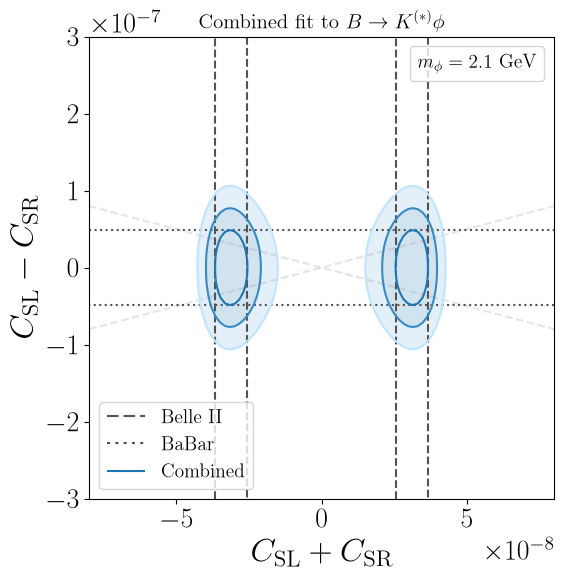

In [4]:
contour_figure(scan_gSgP, (1e-8, 1e-8), r'$C_{\rm SL} + C_{\rm SR}$', r'$C_{\rm SL} - C_{\rm SR}$', r'$m_\phi = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi$', "2body_scalar_scalarcoupling.pdf", shades = 6)

In [5]:
Npts = [100, 100]

model_1 = Model("V", mX = 2.1, CVL = 1e-8/2, CVR = 1e-8/2)
model_2 = Model("V", mX = 2.1, CVL = 1e-8/2, CVR = -1e-8/2)

scan_hVhA = profile_logLL_scan(model_1, model_2, [-3, 3], [-8, 8], pts = Npts)

V, mX = 2.1: 100%|██████████| 10000/10000 [00:04<00:00, 2362.24it/s]


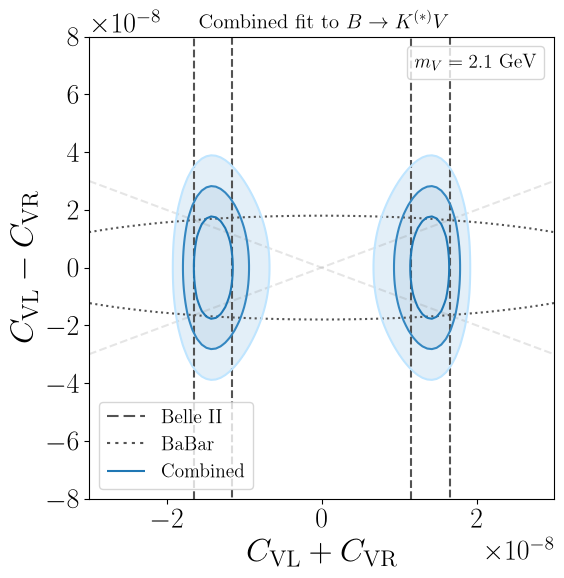

In [6]:
contour_figure(scan_hVhA, (1e-8, 1e-8), r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$', r'$m_V = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} V$', "2body_vector_vectorcoupling.pdf", shades = 200)

In [7]:
Npts = [100, 100]

model_1 = Model("V", mX = 2.1, Lambda = 1e4, CTL = 1e-4/2, CTR = 1e-4/2)
model_2 = Model("V", mX = 2.1, Lambda = 1e4, CTL = 1e-4/2, CTR = -1e-4/2)

scan_hThTt = profile_logLL_scan(model_1, model_2, [-2, 2], [-2, 2], pts = Npts)

V, mX = 2.1: 100%|██████████| 10000/10000 [00:04<00:00, 2343.06it/s]


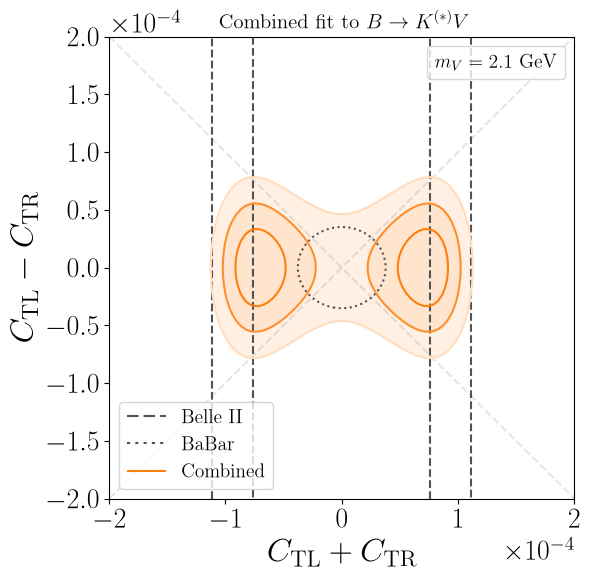

In [8]:
contour_figure(scan_hThTt, (1e-4, 1e-4), r'$C_{\rm TL} + C_{\rm TR}$', r'$C_{\rm TL} - C_{\rm TR}$', r'$m_V = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} V$', "2body_vector_tensorcoupling.pdf", color = 1, shades = 200)

# Three-body scenarios

In [9]:
Npts = [100, 100]

model_1 = Model("phiphi", mX = 0.52, Lambda = 1e4, CSL = 1e-3/2, CSR = 1e-3/2)
model_2 = Model("phiphi", mX = 0.52, Lambda = 1e4, CSL = 1e-3/2, CSR = -1e-3/2)

scan_gSSgPS = profile_logLL_scan(model_1, model_2, [-6, 6], [-10, 10], pts = Npts)

phiphi, mX = 0.52: 100%|██████████| 10000/10000 [00:04<00:00, 2296.71it/s]


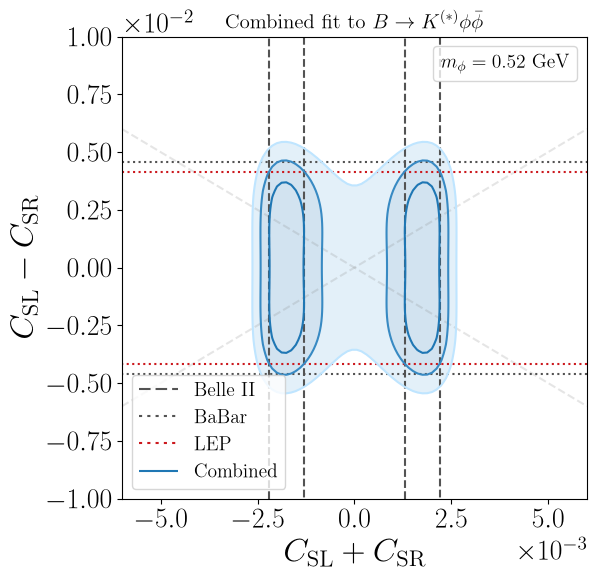

In [10]:
contour_figure(scan_gSSgPS, (1e-3, 1e-3), r'$C_{\rm SL} + C_{\rm SR}$', r'$C_{\rm SL} - C_{\rm SR}$', r'$m_\phi = %1.2f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', "3body_scalar_scalarcoupling.pdf", lep = True, shades = 6)

In [11]:
Npts = [100, 100]

model_1 = Model("phiphi", mX = 0.38, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("phiphi", mX = 0.38, Lambda = 1e4, CVL = 1/2, CVR = -1/2)

scan_gVVgAV = profile_logLL_scan(model_1, model_2, [-20, 20], [-40, 40], pts = Npts)

phiphi, mX = 0.38: 100%|██████████| 10000/10000 [00:04<00:00, 2243.35it/s]


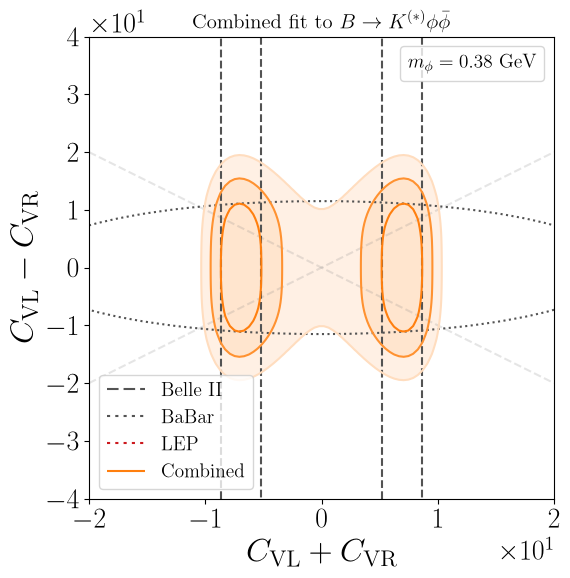

In [12]:
contour_figure(scan_gVVgAV, (1, 1), r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$', r'$m_\phi = %1.2f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', "3body_scalar_vectorcoupling.pdf", lep = True, color = 1, shades = 6)

In [13]:
# fVV - fVA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = 1/2)

scan_fVVfVA = profile_logLL_scan(model_1, model_2, [-6, 6], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2249.32it/s]


In [14]:
# fVV - fAV
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = -1/2)

scan_fVVfAV = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2177.44it/s]


In [15]:
# fVV - fAA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = -1/2)

scan_fVVfAA = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2063.59it/s]


In [16]:
# fAV - fVA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = 1/2)

scan_fAVfVA = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1982.29it/s]


In [17]:
# fAV - fAA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = -1/2)

scan_fAVfAA = profile_logLL_scan(model_1, model_2, [-12, 12], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1943.09it/s]


In [18]:
# fAA - fVA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = 1/2)

scan_fAAfVA = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1917.84it/s]


In [19]:
# fVV - fVA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = 1/2)

scan_fVVfVA_M = profile_logLL_scan(model_1, model_2, [-6, 6], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1944.22it/s]


In [20]:
# fVV - fAV Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = -1/2)

scan_fVVfAV_M = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2043.51it/s]


In [21]:
# fVV - fAA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = -1/2)

scan_fVVfAA_M = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2018.74it/s]


In [22]:
# fAV - fVA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = 1/2)

scan_fAVfVA_M = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1999.58it/s]


In [23]:
# fAV - fAA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = -1/2)

scan_fAVfAA_M = profile_logLL_scan(model_1, model_2, [-12, 12], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1996.08it/s]


In [24]:
# fAA - fVA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = 1/2)

scan_fAAfVA_M = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1917.21it/s]


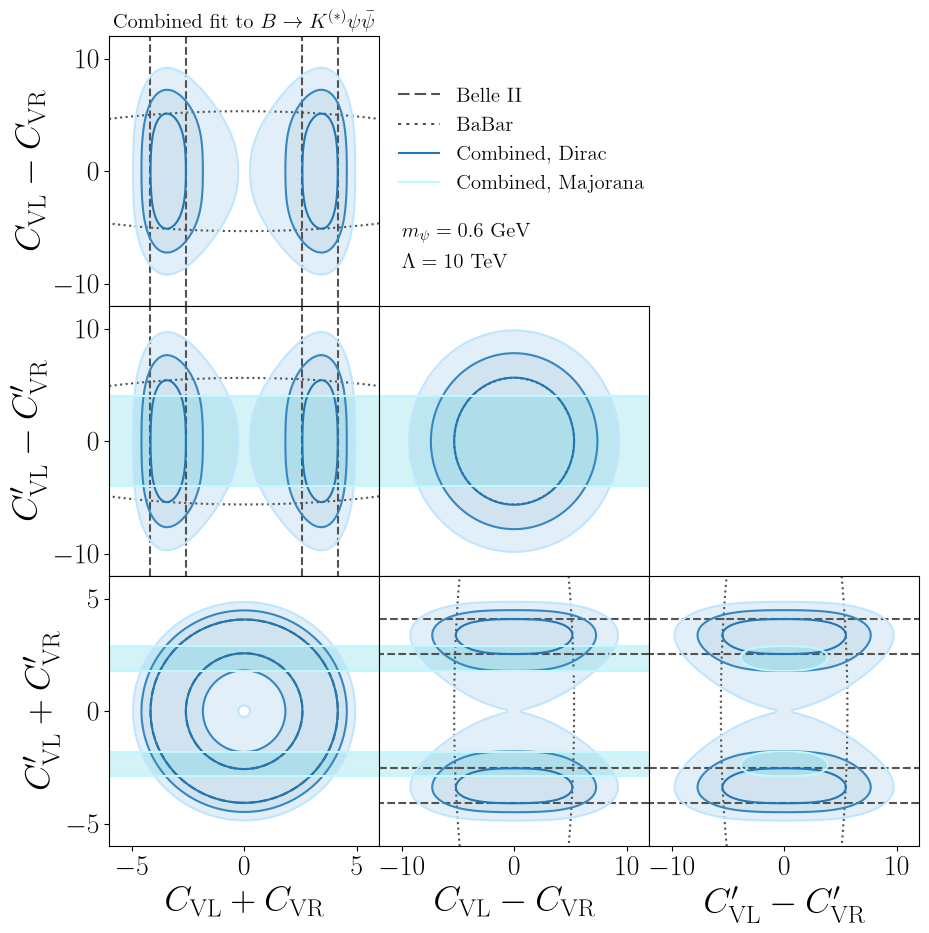

In [25]:
# Fermion pair: six panels of pairs of the vector and axial-vector couplings, Dirac and Majorana
fig = plt.figure(figsize = (9, 9))
VV, AV = r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$'
VA, AA = r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$', r'$C_{\rm VL}^\prime - C_{\rm VR}^\prime$'
panels = [  # axes rectangle, Dirac scan, Majorana scan, x label, y label, hide x ticks, hide y ticks
    ([0.0, 0.0, 0.3, 0.3],  scan_fVVfAV, None,            None, AV,   True,  False),
    ([0.0, -0.3, 0.3, 0.3], scan_fVVfAA, scan_fVVfAA_M,   None, AA,   True,  False),
    ([0.0, -0.6, 0.3, 0.3], scan_fVVfVA, scan_fVVfVA_M,   VV,   VA,   False, False),
    ([0.3, -0.3, 0.3, 0.3], scan_fAVfAA, scan_fAVfAA_M,   None, None, False, True),
    ([0.3, -0.6, 0.3, 0.3], scan_fAVfVA, scan_fAVfVA_M,   AV,   None, False, True),
    ([0.6, -0.6, 0.3, 0.3], scan_fAAfVA, scan_fAAfVA_M,   AA,   None, False, True),
]
axes = []
for rect, scan, scan_M, xlabel, ylabel, hide_x, hide_y in panels:
    ax = fig.add_axes(rect)
    handles = plot_contours(ax, scan, majorana = scan_M, combined_label = 'Combined, Dirac')
    if xlabel: ax.set_xlabel(xlabel, fontsize = 26)
    if ylabel: ax.set_ylabel(ylabel, fontsize = 26)
    if hide_x: ax.set_xticks([])
    if hide_y: ax.set_yticks([])
    axes.append(ax)
axes[0].set_title(r'Combined fit to $B\to K^{(*)} \psi \bar{\psi}$', fontsize = 15)

# Legends, attached to the bottom-left panel
model = scan_fVVfVA.models[0]
blank_1, = axes[2].plot([], [], linewidth = 0)
blank_2, = axes[2].plot([], [], linewidth = 0)
leg1 = axes[2].legend([blank_1, blank_2], [r'$m_\psi = %g$ GeV' % model.mX, r'$\Lambda = %g$ TeV' % (model.Lambda / 1e3)],
                      loc = 'upper right', fontsize = 15, frameon = False, handlelength = 0, handletextpad = 0,
                      bbox_to_anchor = (1.63, 2.38))
axes[2].legend(list(handles.values()), list(handles), loc = 'lower left', fontsize = 15, frameon = False,
               bbox_to_anchor = (1.0, 2.35))
axes[2].add_artist(leg1)

plt.savefig(SAVE_DIR / "3body_fermion_vectorcoupling.pdf", bbox_inches = 'tight')